In [29]:
import pandas as pd

## Porównanie wyników dla różnych modeli

In [30]:
df_gpt = pd.read_csv('../output/final_results/gpt/multi_cross_parent_gpt_mini.csv')
df_gpt.drop(axis=1, columns=["Unnamed: 0"], inplace=True)
df_llama = pd.read_csv('../output/final_results/llama/multi_cross_basic_gpt_mini.csv')
df_llama.drop(axis=1, columns=["Unnamed: 0"], inplace=True)
df_mistral = pd.read_csv('../output/final_results/mistral/multi_cross_basic_gpt_mini.csv')
df_mistral.drop(axis=1, columns=["Unnamed: 0"], inplace=True)

In [31]:
import os
import json

folder_path = "../output/multi_cross_parent"

json_len_list = []
for file_path in os.listdir(folder_path):
    with open(folder_path + "/" + file_path, mode="r", encoding="UTF-8") as f:
        data = json.load(f)
        json_len_list.append(len(data['system_answer']))

In [32]:
import pandas as pd

df_plot = pd.DataFrame({
    "id": df_gpt.index,      
    "json_length": json_len_list,
    "context_semantic_similarity": df_gpt["context_semantic_similarity"],
    "context_precision_with_reference": df_gpt["context_precision_with_reference"],
    "context_recall": df_gpt["context_recall"],
    "faithfulness": df_gpt["faithfulness"],
})

df_plot_sorted = df_plot.sort_values(by="json_length").reset_index(drop=True)


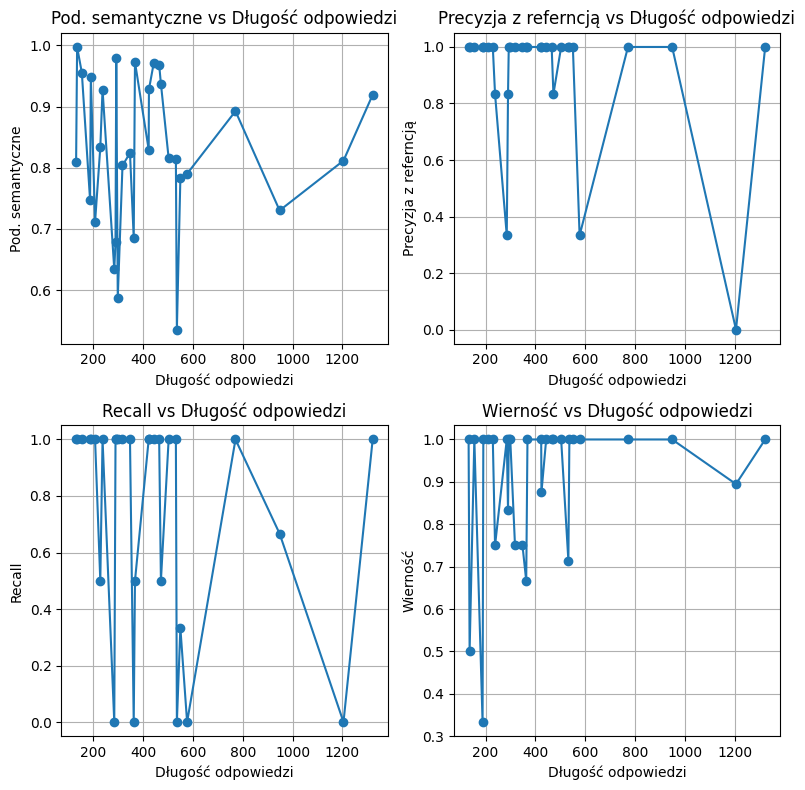

In [33]:
import matplotlib.pyplot as plt

metrics = [
    ("context_semantic_similarity", "Pod. semantyczne"),
    ("context_precision_with_reference", "Precyzja z referncją"),
    ("context_recall", "Recall"),
    ("faithfulness", "Wierność")
]

fig, axes = plt.subplots(2, 2, figsize=(8, 8))  # 2x2 wykresy

for ax, (col, label) in zip(axes.flatten(), metrics):
    ax.plot(df_plot_sorted["json_length"], df_plot_sorted[col], marker="o")
    ax.set_xlabel("Długość odpowiedzi")
    ax.set_ylabel(label)
    ax.set_title(f"{label} vs Długość odpowiedzi")
    ax.grid(True)

plt.tight_layout()
plt.savefig("../images/response_len_vs_metrics.png", dpi=300, bbox_inches="tight")
plt.show()

In [34]:
df_gpt_mean = df_gpt.mean(numeric_only=True).to_frame(name="gpt-4o")
df_llama_mean = df_llama.mean(numeric_only=True).to_frame(name="llama-3.1-70b-instruct")
df_mistral_mean = df_mistral.mean(numeric_only=True).to_frame(name="open-mistral-nemo")

df_means = pd.concat([df_gpt_mean, df_llama_mean, df_mistral_mean], axis=1)

df_means

,gpt-4o,llama-3.1-70b-instruct,open-mistral-nemo
context_precision_without_reference,0.947222,0.869444,0.838889
context_precision_with_reference,0.905556,0.894444,0.916667
context_recall,0.750000,0.775000,0.811111
context_entity_recall,0.139965,0.265752,0.159574
context_noise_sensitivity,0.189991,0.136777,0.245422
context_semantic_similarity,0.827241,0.831655,0.815446
faithfulness,0.902245,0.897050,0.875231
context_response_relevancy,0.324755,0.361992,0.366748
context_factual_correctness,0.488333,0.566667,0.437333
rouge1_precision,0.432134,0.484847,0.419796


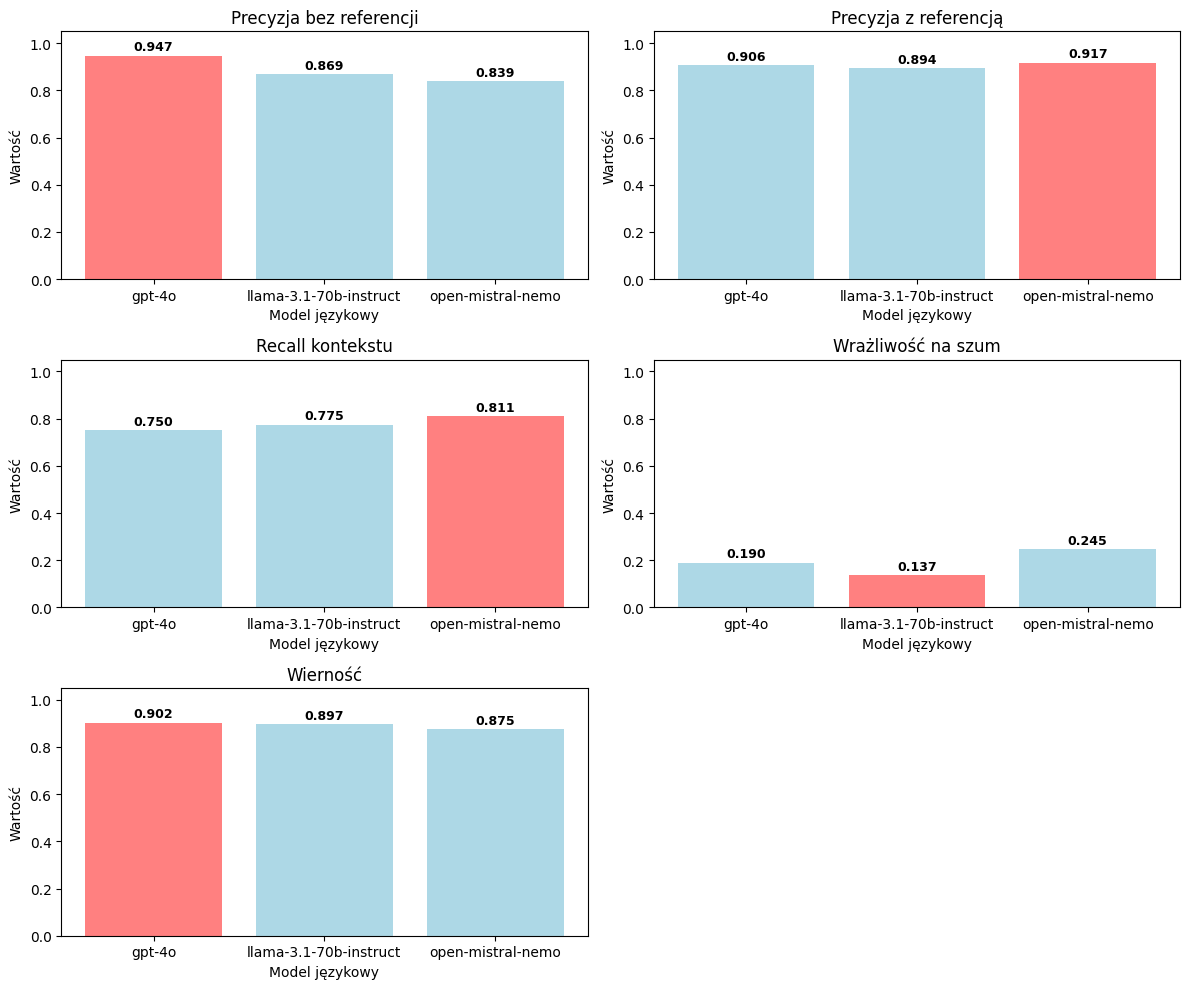

In [35]:
import matplotlib.pyplot as plt

# lista interesujących kolumn
cols = [
    'context_precision_without_reference',
    'context_precision_with_reference',
    'context_recall',
    'context_noise_sensitivity',
    #'context_semantic_similarity',
    'faithfulness'
]

cols_dict = {
    'context_precision_without_reference': 'Precyzja bez referencji',
    'context_precision_with_reference': 'Precyzja z referencją',
    'context_recall': 'Recall kontekstu',
    'context_noise_sensitivity': 'Wrażliwość na szum',
    #'context_semantic_similarity': 'Podobieństwo semantyczne',
    'faithfulness': 'Wierność'
}

# liczba subplotów
n_cols = 2
n_rows = (len(cols) + 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 10))
axes = axes.flatten()

for i, col in enumerate(cols):
    df_plot = df_means.T[[col]].reset_index()
    df_plot.columns = ['method', col]

    # znajdź najlepszą wartość
    if col == 'context_noise_sensitivity':
        best_value = df_plot[col].min()
    else:
        best_value = df_plot[col].max()
    colors = [(1.0, 0.5, 0.5) if v == best_value else 'lightblue' for v in df_plot[col]]

    # słupki
    bars = axes[i].bar(df_plot['method'], df_plot[col], color=colors)

    # etykiety nad słupkami
    for bar in bars:
        yval = bar.get_height()
        axes[i].text(bar.get_x() + bar.get_width()/2, yval + 0.01, f"{yval:.3f}",
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

    axes[i].set_title(cols_dict[col], fontsize=12)
    axes[i].set_ylim(0, 1.05)
    axes[i].tick_params(axis='x', labelrotation=0)
    axes[i].set_xlabel("Model językowy")
    axes[i].set_ylabel("Wartość")
    

# usuń puste osie jeśli są
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.savefig("../images/llm_comparision.png", dpi=300, bbox_inches="tight")
plt.show()

## Porówanie wyników dla różnych modeli oceniających

In [36]:
df_gpt = pd.read_csv('../output/final_results/gpt/multi_cross_parent_gpt_mini.csv')
df_gpt.drop(axis=1, columns=["Unnamed: 0"], inplace=True)
df_llama = pd.read_csv('../output/final_results/gpt/multi_cross_basic_llama.csv')
df_llama.drop(axis=1, columns=["Unnamed: 0"], inplace=True)
df_mistral = pd.read_csv('../output/final_results/gpt/multi_cross_basic_mistral.csv')
df_mistral.drop(axis=1, columns=["Unnamed: 0"], inplace=True)

In [37]:
df_gpt_mean = df_gpt.mean(numeric_only=True).to_frame(name="gpt-4-mini")
df_llama_mean = df_llama.mean(numeric_only=True).to_frame(name="llama3-8b-instruct")
df_mistral_mean = df_mistral.mean(numeric_only=True).to_frame(name="devstral-small-2505")

df_means = pd.concat([df_gpt_mean, df_llama_mean, df_mistral_mean], axis=1)
df_means
df_means[0:7]

,gpt-4-mini,llama3-8b-instruct,devstral-small-2505
context_precision_without_reference,0.947222,0.650000,0.727778
context_precision_with_reference,0.905556,0.697222,0.566667
context_recall,0.750000,0.771111,0.633333
context_entity_recall,0.139965,NaN,NaN
context_noise_sensitivity,0.189991,0.121944,0.215493
context_semantic_similarity,0.827241,0.827391,0.827391
faithfulness,0.902245,0.851111,0.927778


In [38]:
df_means['gpt-4-mini']['context_semantic_similarity'] = 0.827
df_means['llama3-8b-instruct']['context_semantic_similarity'] = 0.827
df_means['devstral-small-2505']['context_semantic_similarity'] = 0.827

C:\Users\adam6\AppData\Local\Temp\ipykernel_26972\136795146.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df_means['gpt-4-mini']['context_semantic_similarity'] = 0.827
C:\Users\adam6\AppData\Local\Temp\ipykernel_26972\136795146.py:2: F

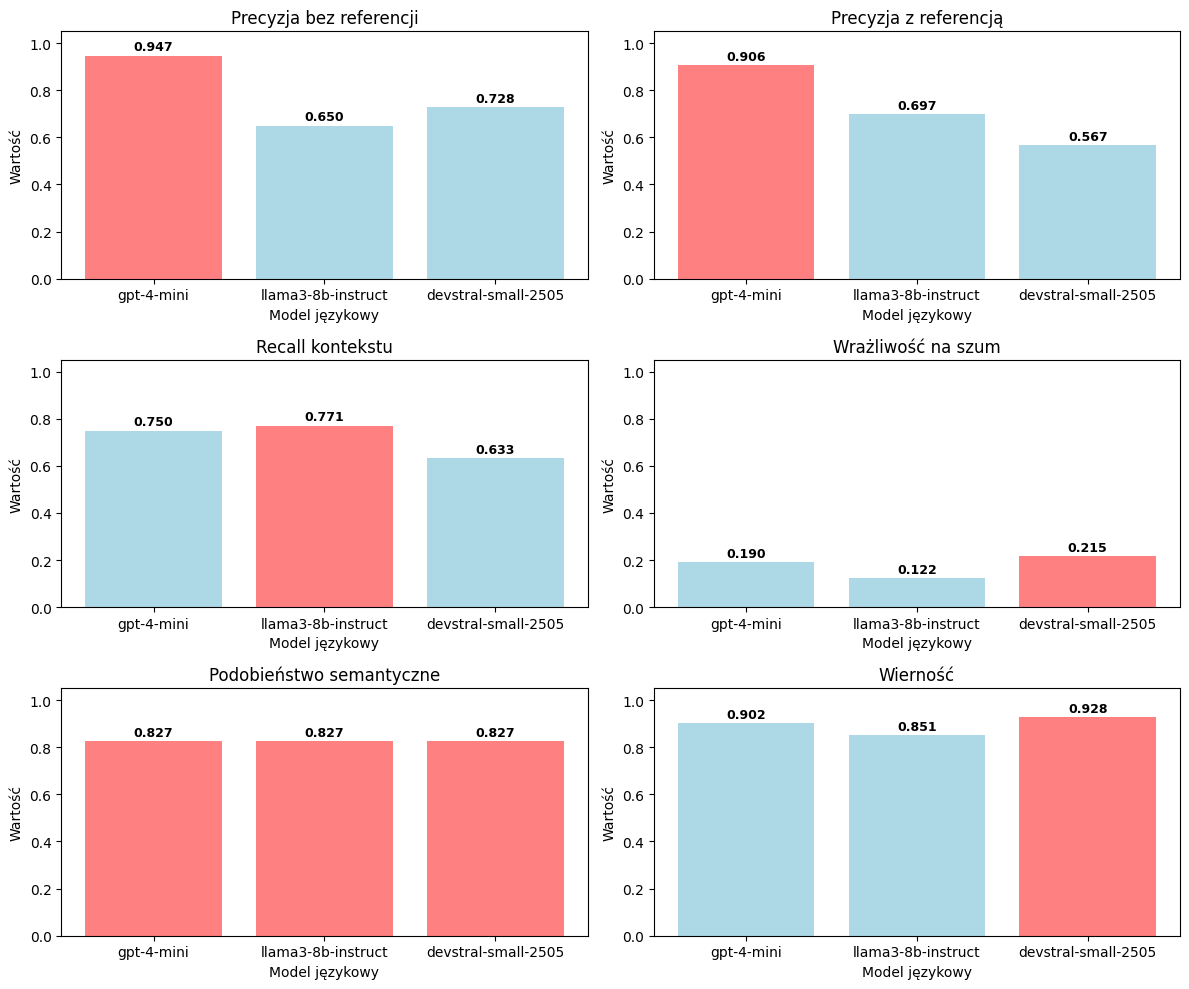

In [39]:
import matplotlib.pyplot as plt

# lista interesujących kolumn
cols = [
    'context_precision_without_reference',
    'context_precision_with_reference',
    'context_recall',
    'context_noise_sensitivity',
    'context_semantic_similarity',
    'faithfulness'
]

cols_dict = {
    'context_precision_without_reference': 'Precyzja bez referencji',
    'context_precision_with_reference': 'Precyzja z referencją',
    'context_recall': 'Recall kontekstu',
    'context_noise_sensitivity': 'Wrażliwość na szum',
    'context_semantic_similarity': 'Podobieństwo semantyczne',
    'faithfulness': 'Wierność'
}

# liczba subplotów
n_cols = 2
n_rows = (len(cols) + 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 10))
axes = axes.flatten()

for i, col in enumerate(cols):
    df_plot = df_means.T[[col]].reset_index()
    df_plot.columns = ['method', col]

    # znajdź najlepszą wartość
    best_value = df_plot[col].max()
    colors = [(1.0, 0.5, 0.5) if v == best_value else 'lightblue' for v in df_plot[col]]

    # słupki
    bars = axes[i].bar(df_plot['method'], df_plot[col], color=colors)

    # etykiety nad słupkami
    for bar in bars:
        yval = bar.get_height()
        axes[i].text(bar.get_x() + bar.get_width()/2, yval + 0.01, f"{yval:.3f}",
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

    axes[i].set_title(cols_dict[col], fontsize=12)
    axes[i].set_ylim(0, 1.05)
    axes[i].tick_params(axis='x', labelrotation=0)
    axes[i].set_xlabel("Model językowy")
    axes[i].set_ylabel("Wartość")
    

# usuń puste osie jeśli są
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.savefig("../images/llm_scorer_comparision.png", dpi=300, bbox_inches="tight")
plt.show()

# Porówananie wyników dla różnych modułów

In [40]:
df_aqua = pd.read_csv('../output/final_results/gpt/multi_cross_parent_gpt_mini.csv')
df_aqua.drop(axis=1, columns=["Unnamed: 0"], inplace=True)
df_query = pd.read_csv('../output/final_results/gpt/multi_parent_gpt_mini.csv')
df_query.drop(axis=1, columns=["Unnamed: 0"], inplace=True)
df_cross = pd.read_csv('../output/final_results/gpt/cross_parent_gpt_mini.csv')
df_cross.drop(axis=1, columns=["Unnamed: 0"], inplace=True)
df_basic = pd.read_csv('../output/final_results/gpt/basic_parent_gpt_mini.csv')
df_basic.drop(axis=1, columns=["Unnamed: 0"], inplace=True)

In [41]:
df_aqua_mean = df_aqua.mean(numeric_only=True).to_frame(name="AquaRag")
df_query_mean = df_query.mean(numeric_only=True).to_frame(name="AquaRAG\n-multi\n-query")
df_cross_mean = df_cross.mean(numeric_only=True).to_frame(name="AquaRag\n-re-ranking")
df_basic_mean = df_basic.mean(numeric_only=True).to_frame(name="AquaRAG\n-no-upgrades")

df_means = pd.concat([df_aqua_mean, df_query_mean, df_cross_mean, df_basic_mean], axis=1)
df_means

,AquaRag,AquaRAG\n-multi\n-query,AquaRag\n-re-ranking,AquaRAG\n-no-upgrades
context_precision_without_reference,0.947222,0.816667,0.930556,0.875000
context_precision_with_reference,0.905556,0.883333,0.886111,0.752778
context_recall,0.750000,0.646111,0.872222,0.642222
context_entity_recall,0.139965,0.161207,0.235340,0.070357
context_noise_sensitivity,0.189991,0.248988,0.204921,0.152446
context_semantic_similarity,0.827241,0.796107,0.837365,0.776400
faithfulness,0.902245,0.851389,0.906164,0.767619
context_response_relevancy,0.324755,0.330975,0.321083,0.304817
context_factual_correctness,0.488333,0.402333,0.552333,0.214667
rouge1_precision,0.432134,0.373010,0.476152,0.266903


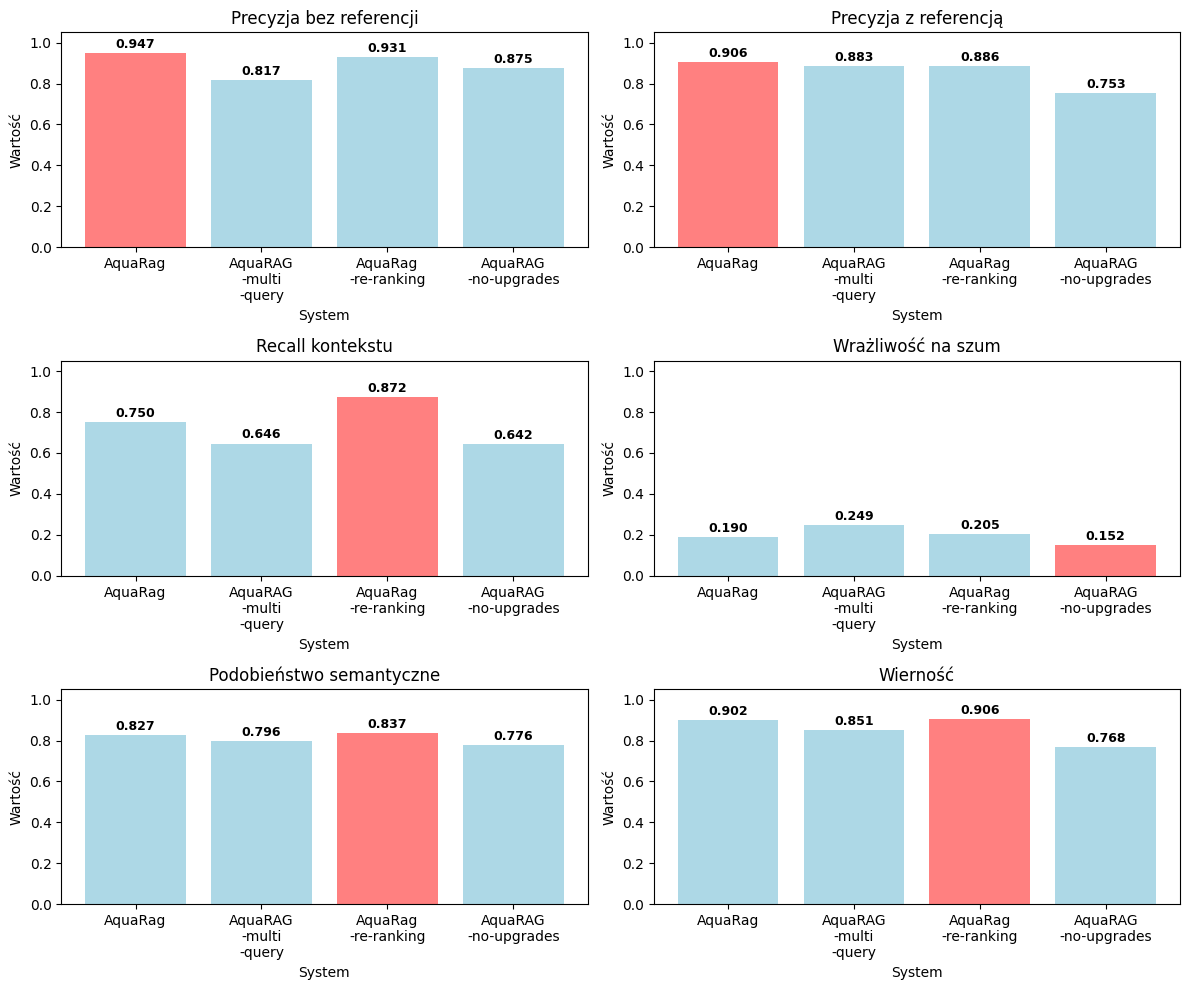

In [42]:
import matplotlib.pyplot as plt

# lista interesujących kolumn
cols = [
    'context_precision_without_reference',
    'context_precision_with_reference',
    'context_recall',
    'context_noise_sensitivity',
    'context_semantic_similarity',
    'faithfulness'
]

cols_dict = {
    'context_precision_without_reference': 'Precyzja bez referencji',
    'context_precision_with_reference': 'Precyzja z referencją',
    'context_recall': 'Recall kontekstu',
    'context_noise_sensitivity': 'Wrażliwość na szum',
    'context_semantic_similarity': 'Podobieństwo semantyczne',
    'faithfulness': 'Wierność'
}

# liczba subplotów
n_cols = 2
n_rows = (len(cols) + 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 10))
axes = axes.flatten()

for i, col in enumerate(cols):
    df_plot = df_means.T[[col]].reset_index()
    df_plot.columns = ['method', col]

    # znajdź najlepszą wartość
    if col == 'context_noise_sensitivity':
        best_value = df_plot[col].min()
    else:
        best_value = df_plot[col].max()
    colors = [(1.0, 0.5, 0.5) if v == best_value else 'lightblue' for v in df_plot[col]]

    # słupki
    bars = axes[i].bar(df_plot['method'], df_plot[col], color=colors)

    # etykiety nad słupkami
    for bar in bars:
        yval = bar.get_height()
        axes[i].text(bar.get_x() + bar.get_width()/2, yval + 0.01, f"{yval:.3f}",
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

    axes[i].set_title(cols_dict[col], fontsize=12)
    axes[i].set_ylim(0, 1.05)
    axes[i].tick_params(axis='x', labelrotation=0)
    axes[i].set_xlabel("System")
    axes[i].set_ylabel("Wartość")
    

# usuń puste osie jeśli są
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.savefig("../images/system_comparision.png", dpi=300, bbox_inches="tight")
plt.show()


# Porówananie dla różnych metod indeksowania

In [43]:
df_parent= pd.read_csv('../output/final_results/gpt/multi_cross_parent_gpt_mini.csv')
df_parent.drop(axis=1, columns=["Unnamed: 0"], inplace=True)
df_basic = pd.read_csv('../output/final_results/gpt/multi_cross_basic_gpt_mini.csv')
df_basic.drop(axis=1, columns=["Unnamed: 0"], inplace=True)

df_parent_mean = df_parent.mean(numeric_only=True).to_frame(name="Indeksowanie\nz rodzicem")
df_basic_mean = df_basic.mean(numeric_only=True).to_frame(name="Indeksowanie podstawowe")

df_means = pd.concat([df_parent_mean, df_basic_mean], axis=1)
df_means

,Indeksowanie\nz rodzicem,Indeksowanie podstawowe
context_precision_without_reference,0.947222,0.758486
context_precision_with_reference,0.905556,0.748300
context_recall,0.750000,0.706389
context_entity_recall,0.139965,0.256219
context_noise_sensitivity,0.189991,0.169493
context_semantic_similarity,0.827241,0.841795
faithfulness,0.902245,0.855801
context_response_relevancy,0.324755,0.377662
context_factual_correctness,0.488333,0.565667
rouge1_precision,0.432134,0.484707


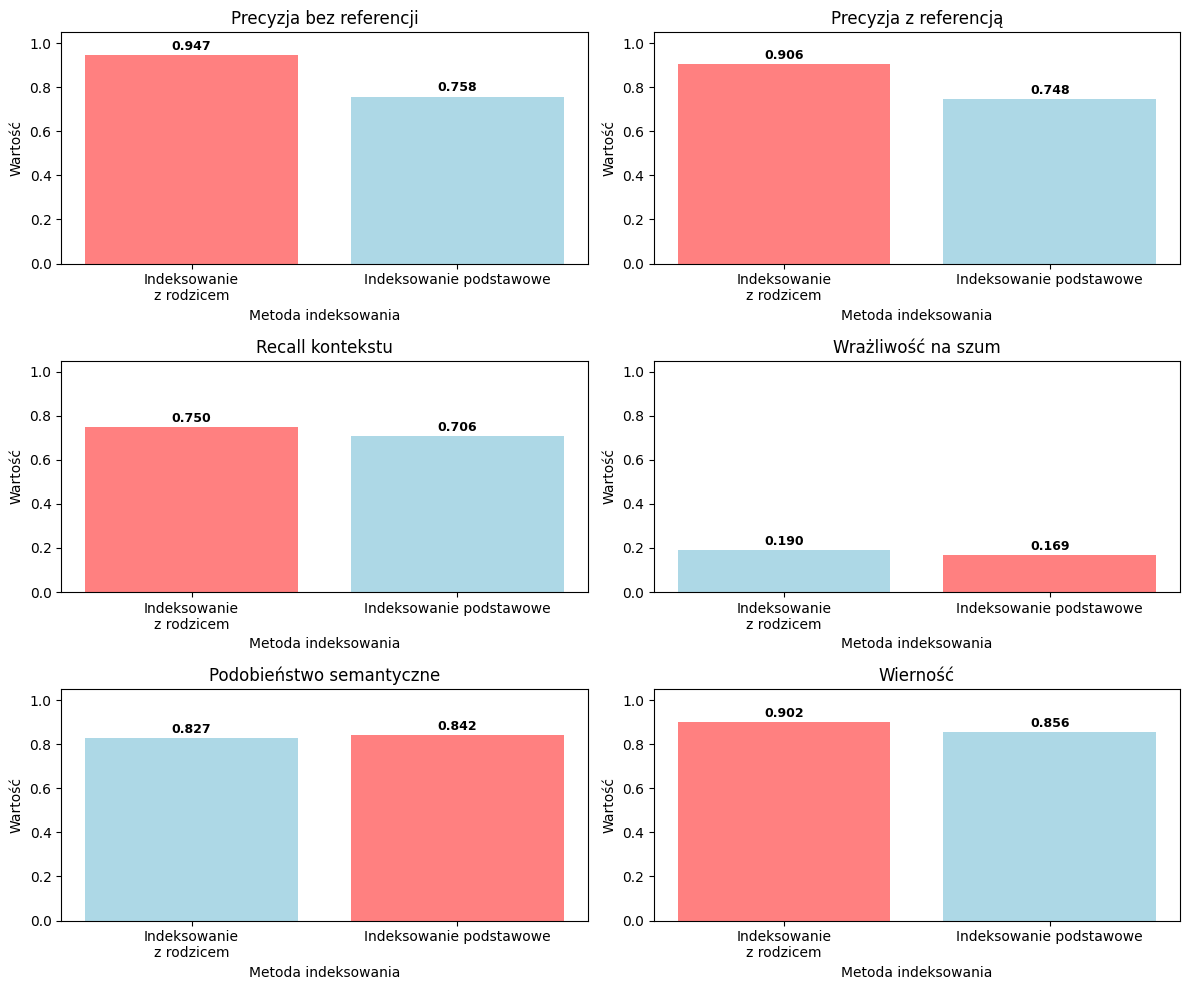

In [44]:
import matplotlib.pyplot as plt

# lista interesujących kolumn
cols = [
    'context_precision_without_reference',
    'context_precision_with_reference',
    'context_recall',
    'context_noise_sensitivity',
    'context_semantic_similarity',
    'faithfulness'
]

cols_dict = {
    'context_precision_without_reference': 'Precyzja bez referencji',
    'context_precision_with_reference': 'Precyzja z referencją',
    'context_recall': 'Recall kontekstu',
    'context_noise_sensitivity': 'Wrażliwość na szum',
    'context_semantic_similarity': 'Podobieństwo semantyczne',
    'faithfulness': 'Wierność'
}

# liczba subplotów
n_cols = 2
n_rows = (len(cols) + 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 10))
axes = axes.flatten()

for i, col in enumerate(cols):
    df_plot = df_means.T[[col]].reset_index()
    df_plot.columns = ['method', col]

    # znajdź najlepszą wartość
    if col == 'context_noise_sensitivity':
        best_value = df_plot[col].min()
    else:
        best_value = df_plot[col].max()
    colors = [(1.0, 0.5, 0.5) if v == best_value else 'lightblue' for v in df_plot[col]]

    # słupki
    bars = axes[i].bar(df_plot['method'], df_plot[col], color=colors)

    # etykiety nad słupkami
    for bar in bars:
        yval = bar.get_height()
        axes[i].text(bar.get_x() + bar.get_width()/2, yval + 0.01, f"{yval:.3f}",
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

    axes[i].set_title(cols_dict[col], fontsize=12)
    axes[i].set_ylim(0, 1.05)
    axes[i].tick_params(axis='x', labelrotation=0)
    axes[i].set_xlabel("Metoda indeksowania")
    axes[i].set_ylabel("Wartość")
    

# usuń puste osie jeśli są
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.savefig("../images/indexing_comparision.png", dpi=300, bbox_inches="tight")
plt.show()


In [45]:
rows = df_parent[df_parent['context_precision_without_reference'] == 0].index.tolist()
folder_path = "../output/multi_cross_parent"

json_obj_list = []
for file_path in os.listdir(folder_path):
    with open(folder_path + "/" + file_path, mode="r", encoding="UTF-8") as f:
        data = json.load(f)
        json_obj_list.append(data)
        
json_obj_list[rows[0]]

{'question': 'Kto ponosi koszty wykonania oraz kto odpowiada za utrzymanie dróg, urządzeń do przepędzania zwierząt i przejazdów przez wały przeciwpowodziowe?',
 'system_answer': 'Na podstawie dostępnych dokumentów, nie ma bezpośredniej informacji dotyczącej tego, kto ponosi koszty wykonania oraz kto odpowiada za utrzymanie dróg, urządzeń do przepędzania zwierząt i przejazdów przez wały przeciwpowodziowe. Dokumenty zawierają informacje o zarządzaniu wałami przeciwpowodziowymi, w tym o wprowadzaniu zakazów poruszania się po wałach oraz o usuwaniu drzew i krzewów dla zapewnienia ich szczelności i stabilności, ale nie odnoszą się bezpośrednio do kwestii kosztów i odpowiedzialności za utrzymanie dróg i urządzeń związanych z wałami przeciwpowodziowymi.',
 'parent_ids': ['8788949c-3f31-4228-b17a-694d53985b6c',
  'bfd8eb46-b8a9-4033-a981-9da5944fd48b',
  'c2e18c87-5a09-4f20-a306-22865f21d117'],
 'child_ids': ['0be936cf-4dda-43be-822a-18f21b849126',
  '98607208-acaa-4305-acf9-f224da4dbefe',
  '

In [46]:
import sys
sys.path.append(os.path.abspath(".."))

In [47]:
folder_path = "../output/multi_cross_parent"

json_obj_list = []
for file_path in os.listdir(folder_path):
    with open(folder_path + "/" + file_path, mode="r", encoding="UTF-8") as f:
        data = json.load(f)
        json_obj_list.append(data)

In [48]:
mean_length_answer_list = []
for item in json_obj_list:
    mean_length = len(item['system_answer'])
    mean_length_answer_list.append(mean_length)

In [49]:
df_aqua = pd.read_csv('../output/final_results/nlp/multi_cross_parent_distances.csv')
df_aqua.drop(axis=1, columns=['Unnamed: 0'], inplace=True)
df_multi = pd.read_csv('../output/final_results/nlp/multi_parent_distances.csv')
df_multi.drop(axis=1, columns=['Unnamed: 0'], inplace=True)
df_cross = pd.read_csv('../output/final_results/nlp/cross_parent_distances.csv')
df_cross.drop(axis=1, columns=['Unnamed: 0'], inplace=True)
df_basic = pd.read_csv('../output/final_results/nlp/basic_parent_distances.csv')
df_basic.drop(axis=1, columns=['Unnamed: 0'], inplace=True)

In [50]:
df_aqua_mean = df_aqua.mean().to_frame(name="AquaRAG")
df_multi_mean = df_multi.mean(numeric_only=True).to_frame(name="AquaRAG\n-multi\n-query")
df_cross_mean = df_cross.mean(numeric_only=True).to_frame(name="AquaRag\n-re-ranking")
df_basic_mean = df_basic.mean(numeric_only=True).to_frame(name="AquaRAG\n-no-upgrades")
df_means = pd.concat([df_aqua_mean, df_multi_mean, df_cross_mean, df_basic_mean], axis=1)
df_means

,AquaRAG,AquaRAG\n-multi\n-query,AquaRag\n-re-ranking,AquaRAG\n-no-upgrades
lev_scores,0.468120,0.376315,0.504833,0.322149
ham_scores,0.194009,0.137797,0.189351,0.126553
jaro_scores,0.736718,0.691526,0.741400,0.689357
jw_scores,0.761125,0.717655,0.770711,0.720596


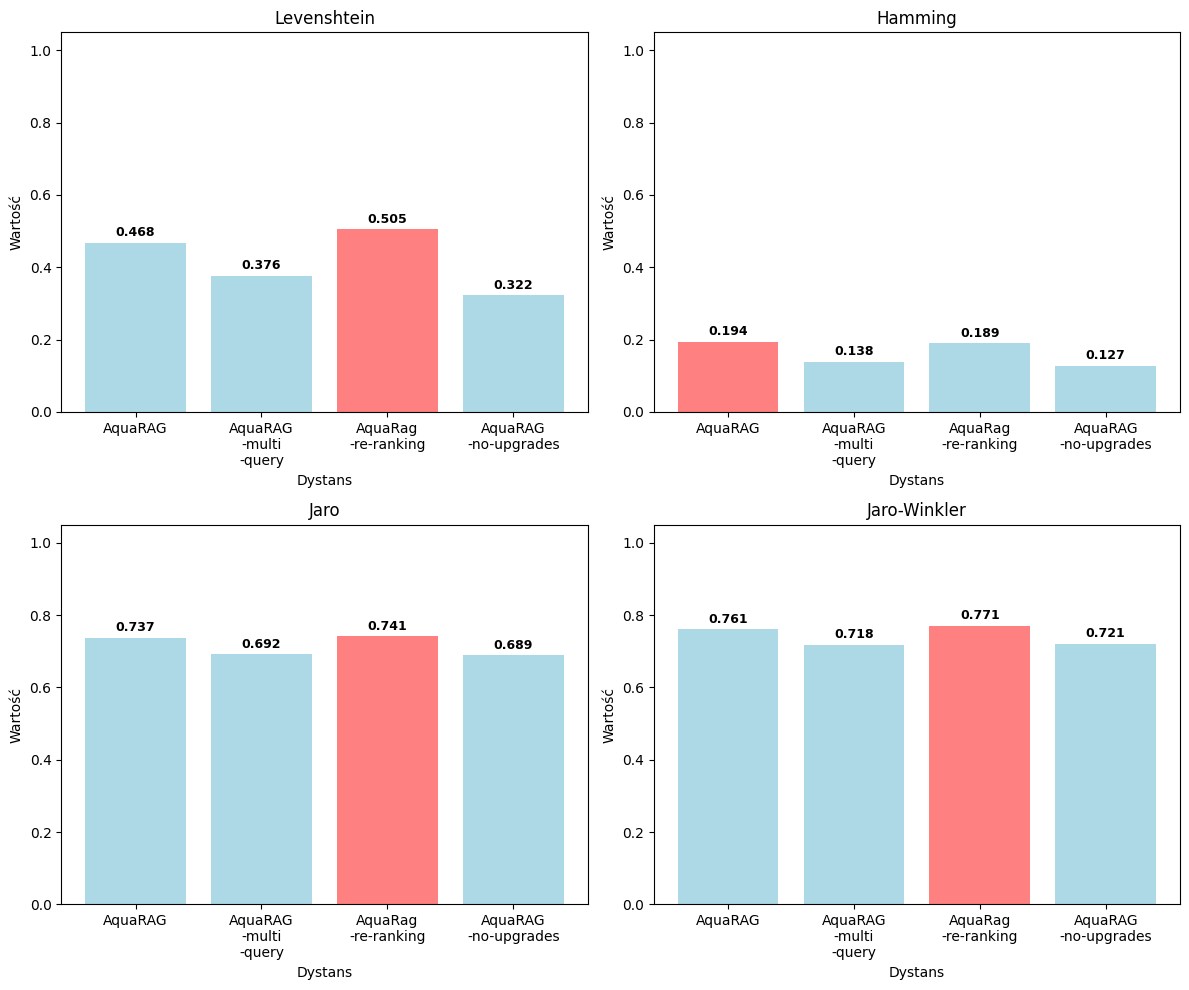

In [51]:
cols = [
    'lev_scores',
    'ham_scores',
    'jaro_scores',
    'jw_scores',
]

cols_dict = {
    'lev_scores': 'Levenshtein',
    'ham_scores': 'Hamming',
    'jaro_scores': 'Jaro',
    'jw_scores': 'Jaro-Winkler',
}

n_cols = 2
n_rows = (len(cols) + 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 10))
axes = axes.flatten()

for i, col in enumerate(cols):
    df_plot = df_means.T[[col]].reset_index()
    df_plot.columns = ['method', col]

    # znajdź najlepszą wartość
    if col == 'context_noise_sensitivity':
        best_value = df_plot[col].min()
    else:
        best_value = df_plot[col].max()
    colors = [(1.0, 0.5, 0.5) if v == best_value else 'lightblue' for v in df_plot[col]]

    # słupki
    bars = axes[i].bar(df_plot['method'], df_plot[col], color=colors)

    # etykiety nad słupkami
    for bar in bars:
        yval = bar.get_height()
        axes[i].text(bar.get_x() + bar.get_width()/2, yval + 0.01, f"{yval:.3f}",
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

    axes[i].set_title(cols_dict[col], fontsize=12)
    axes[i].set_ylim(0, 1.05)
    axes[i].tick_params(axis='x', labelrotation=0)
    axes[i].set_xlabel("Dystans")
    axes[i].set_ylabel("Wartość")
    

# usuń puste osie jeśli są
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.savefig("../images/distances_comparision.png", dpi=300, bbox_inches="tight")
plt.show()


In [52]:
df_rouge = pd.read_csv('../output/final_results/gpt/multi_cross_parent.csv')
df_rouge = df_rouge[['rouge1_precision', 'rouge1_recall', 'rouge1_f1','rouge2_precision', 'rouge2_recall', 'rouge2_f1','rougel_precision', 'rougel_recall', 'rougel_f1']]

In [53]:
df_aqua = pd.read_csv('../output/final_results/gpt/multi_cross_parent_gpt_mini.csv')
df_aqua = df_aqua[['rouge1_precision', 'rouge1_recall', 'rouge1_f1','rouge2_precision', 'rouge2_recall', 'rouge2_f1','rougel_precision', 'rougel_recall', 'rougel_f1']]
df_query = pd.read_csv('../output/final_results/gpt/multi_parent_gpt_mini.csv')
df_query = df_query[['rouge1_precision', 'rouge1_recall', 'rouge1_f1','rouge2_precision', 'rouge2_recall', 'rouge2_f1','rougel_precision', 'rougel_recall', 'rougel_f1']]
df_cross = pd.read_csv('../output/final_results/gpt/cross_parent_gpt_mini.csv')
df_cross = df_cross[['rouge1_precision', 'rouge1_recall', 'rouge1_f1','rouge2_precision', 'rouge2_recall', 'rouge2_f1','rougel_precision', 'rougel_recall', 'rougel_f1']]
df_basic = pd.read_csv('../output/final_results/gpt/basic_parent_gpt_mini.csv')
df_basic = df_basic[['rouge1_precision', 'rouge1_recall', 'rouge1_f1','rouge2_precision', 'rouge2_recall', 'rouge2_f1','rougel_precision', 'rougel_recall', 'rougel_f1']]

In [54]:
df_aqua_mean = df_aqua.mean().to_frame(name="AquaRAG")
df_multi_mean = df_query.mean(numeric_only=True).to_frame(name="AquaRAG\n-multi\n-query")
df_cross_mean = df_cross.mean(numeric_only=True).to_frame(name="AquaRag\n-re-ranking")
df_basic_mean = df_basic.mean(numeric_only=True).to_frame(name="AquaRAG\n-no-upgrades")
df_means = pd.concat([df_aqua_mean, df_multi_mean, df_cross_mean, df_basic_mean], axis=1)
df_means

,AquaRAG,AquaRAG\n-multi\n-query,AquaRag\n-re-ranking,AquaRAG\n-no-upgrades
rouge1_precision,0.432134,0.373010,0.476152,0.266903
rouge1_recall,0.618352,0.527184,0.637458,0.412470
rouge1_f1,0.477800,0.398600,0.515718,0.296481
rouge2_precision,0.327400,0.258025,0.356899,0.146781
rouge2_recall,0.468210,0.365591,0.464940,0.209557
rouge2_f1,0.361356,0.277804,0.385449,0.158687
rougel_precision,0.395771,0.320630,0.430889,0.212083
rougel_recall,0.572723,0.466365,0.579185,0.329676
rougel_f1,0.439356,0.348083,0.468239,0.237054


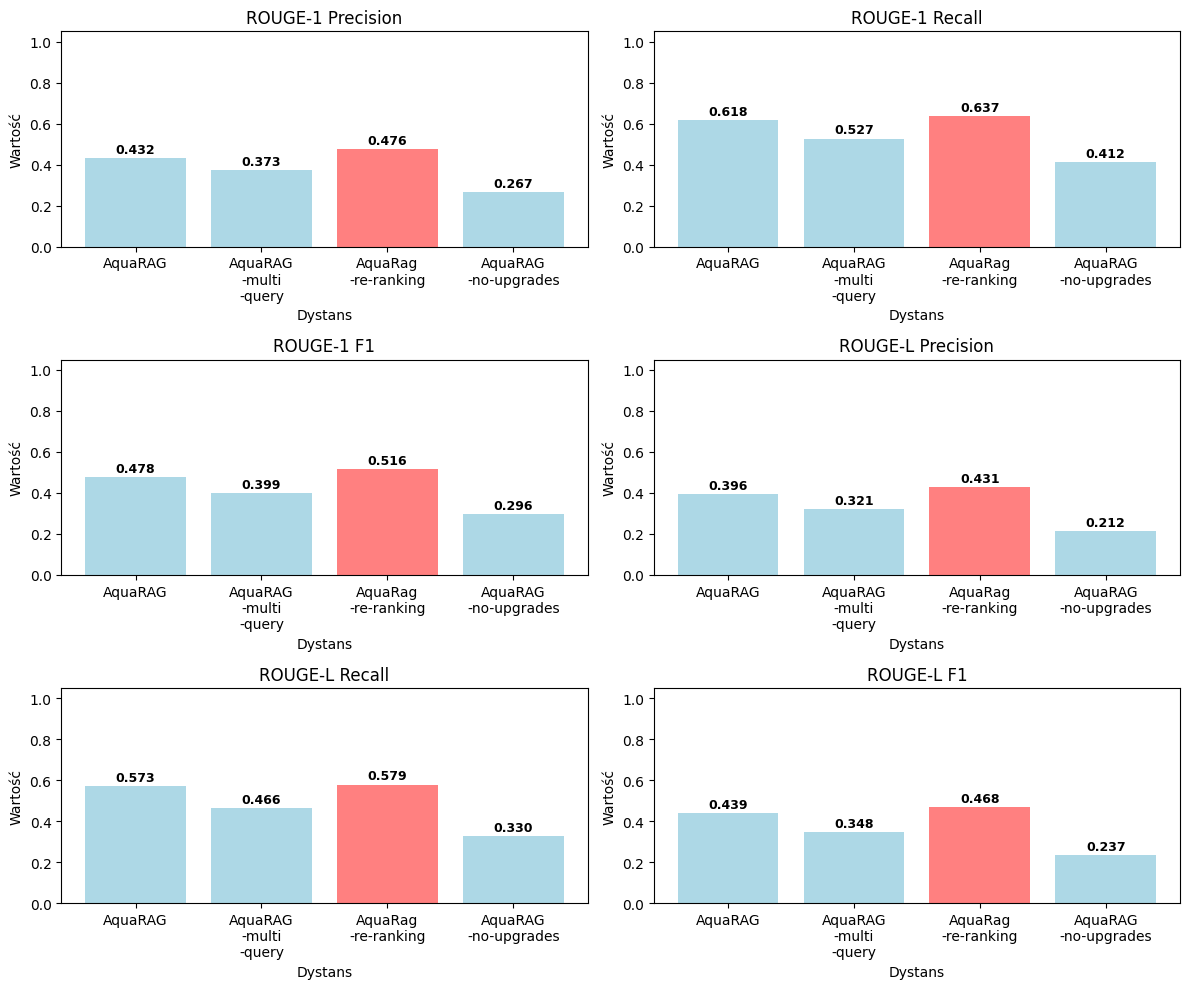

In [55]:
cols = [
    'rouge1_precision',
    'rouge1_recall',
    'rouge1_f1',
    'rougel_precision',
    'rougel_recall',
    'rougel_f1',
]

cols_dict = {
    'rouge1_precision': 'ROUGE-1 Precision',
    'rouge1_recall': 'ROUGE-1 Recall',
    'rouge1_f1': 'ROUGE-1 F1',
    'rougel_precision': 'ROUGE-L Precision',
    'rougel_recall': 'ROUGE-L Recall',
    'rougel_f1': 'ROUGE-L F1',
}


n_cols = 2
n_rows = (len(cols) + 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 10))
axes = axes.flatten()

for i, col in enumerate(cols):
    df_plot = df_means.T[[col]].reset_index()
    df_plot.columns = ['method', col]

    # znajdź najlepszą wartość
    if col == 'context_noise_sensitivity':
        best_value = df_plot[col].min()
    else:
        best_value = df_plot[col].max()
    colors = [(1.0, 0.5, 0.5) if v == best_value else 'lightblue' for v in df_plot[col]]

    # słupki
    bars = axes[i].bar(df_plot['method'], df_plot[col], color=colors)

    # etykiety nad słupkami
    for bar in bars:
        yval = bar.get_height()
        axes[i].text(bar.get_x() + bar.get_width()/2, yval + 0.01, f"{yval:.3f}",
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

    axes[i].set_title(cols_dict[col], fontsize=12)
    axes[i].set_ylim(0, 1.05)
    axes[i].tick_params(axis='x', labelrotation=0)
    axes[i].set_xlabel("Dystans")
    axes[i].set_ylabel("Wartość")
    

# usuń puste osie jeśli są
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.savefig("../images/rouge_comparision.png", dpi=300, bbox_inches="tight")
plt.show()
